# MNIST above 99% with a CNN and Optuna

SYDE 577. Every model choice below is made on a validation set carved out of the 60k training images. The test set isn't loaded until the final section.

In [1]:
# This block is Generated from Anthropic Claude
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import MNIST

SEED = 577
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Training cells cache their results in results/ and only run what is missing.

print(DEVICE, torch.__version__, optuna.__version__)

/Users/celine/Documents/school/tron/syde577/mnist_cnn/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mps 2.15.0 5.0.0


## Data: train, validation and test splits

The 60k training images are split into about 50k train and 10k validation, stratified by digit with a fixed seed. Normalization statistics come from the train split only, so nothing about the held-out images reaches the model.

In [2]:
# This block is Generated from Anthropic Claude
mnist_train = MNIST(DATA_DIR, train=True, download=True)
X_all = mnist_train.data.float().unsqueeze(1) / 255.0
y_all = mnist_train.targets

split_rng = np.random.default_rng(SEED)
val_idx = []
for digit in range(10):
    digit_idx = np.flatnonzero(y_all.numpy() == digit)
    split_rng.shuffle(digit_idx)
    val_idx.append(digit_idx[: round(len(digit_idx) / 6)])
val_idx = np.sort(np.concatenate(val_idx))
train_idx = np.setdiff1d(np.arange(len(X_all)), val_idx)

assert len(np.intersect1d(train_idx, val_idx)) == 0
assert len(train_idx) + len(val_idx) == len(X_all)

MEAN = X_all[train_idx].mean().item()
STD = X_all[train_idx].std().item()
BACKGROUND = (0.0 - MEAN) / STD

X_train = ((X_all[train_idx] - MEAN) / STD).to(DEVICE)
y_train = y_all[train_idx].to(DEVICE)
X_val = ((X_all[val_idx] - MEAN) / STD).to(DEVICE)
y_val = y_all[val_idx].to(DEVICE)

print(f"train {len(X_train)}, val {len(X_val)}, mean {MEAN:.4f}, std {STD:.4f}")
print("val per class:", torch.bincount(y_val.cpu(), minlength=10).tolist())

train 49999, val 10001, mean 0.1307, std 0.3081
val per class: [987, 1124, 993, 1022, 974, 904, 986, 1044, 975, 992]


## Shared model, augmentation and training code

The network is a stack of conv blocks. Each block is two 3×3 convolutions, optional BatchNorm, ReLU and a 2×2 max pool, and the filter count doubles per block. The head is either flatten or global average pooling, followed by dropout and one linear layer.

Augmentation runs on whole batches on the GPU, with separate random parameters per image. It's only applied to training batches. There are no flips or large rotations, because a mirrored digit isn't a digit and a 6 turned 180° is a 9.

In [3]:
# This block is Generated from Anthropic Claude
BASELINE = {
    "n_blocks": 2, "base_filters": 32, "use_batchnorm": False, "head": "flatten",
    "dropout": 0.0, "weight_decay": 0.0, "label_smoothing": 0.0,
    "rotation": 0.0, "translate": 0.0, "scale_jitter": 0.0, "shear": 0.0, "cutout": 0,
    "lr": 1e-3, "schedule": "constant", "batch_size": 128,
}


class CNN(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        layers = []
        in_ch = 1
        for block in range(cfg["n_blocks"]):
            out_ch = cfg["base_filters"] * 2**block
            for _ in range(2):
                layers.append(nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=not cfg["use_batchnorm"]))
                if cfg["use_batchnorm"]:
                    layers.append(nn.BatchNorm2d(out_ch))
                layers.append(nn.ReLU())
                in_ch = out_ch
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        size = 28 // 2 ** cfg["n_blocks"]
        self.use_gap = cfg["head"] == "gap"
        self.dropout = nn.Dropout(cfg["dropout"])
        self.fc = nn.Linear(in_ch if self.use_gap else in_ch * size * size, 10)

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3)) if self.use_gap else x.flatten(1)
        return self.fc(self.dropout(x))


def augment(x, cfg):
    n = x.size(0)
    if cfg["rotation"] or cfg["translate"] or cfg["scale_jitter"] or cfg["shear"]:
        u = lambda limit: (torch.rand(n, device=x.device) * 2 - 1) * limit
        angle = u(math.radians(cfg["rotation"]))
        scale = 1 + u(cfg["scale_jitter"])
        shear = u(math.radians(cfg["shear"]))
        cos, sin = torch.cos(angle), torch.sin(angle)
        # image width is 2 in normalized grid coordinates, so translation is doubled
        theta = torch.stack([
            torch.stack([cos / scale, (-sin + shear * cos) / scale, u(cfg["translate"]) * 2], dim=1),
            torch.stack([sin / scale, (cos + shear * sin) / scale, u(cfg["translate"]) * 2], dim=1),
        ], dim=1)
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        # grid_sample pads with 0, so shift so that padding matches the digit background
        x = F.grid_sample(x - BACKGROUND, grid, align_corners=False) + BACKGROUND
    if cfg["cutout"]:
        size = cfg["cutout"]
        cx = torch.randint(0, 28, (n, 1, 1), device=x.device)
        cy = torch.randint(0, 28, (n, 1, 1), device=x.device)
        coords = torch.arange(28, device=x.device)
        in_x = (coords[None, None, :] - cx).abs() <= size // 2
        in_y = (coords[None, :, None] - cy).abs() <= size // 2
        x = x.masked_fill((in_x & in_y)[:, None], BACKGROUND)
    return x


@torch.no_grad()
def accuracy(model, X, y, batch_size=2048):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        correct += (model(X[i : i + batch_size]).argmax(1) == y[i : i + batch_size]).sum().item()
    return correct / len(X)


def run_training(cfg, seed, epochs, trial=None):
    torch.manual_seed(seed)
    perm_gen = torch.Generator().manual_seed(seed)
    model = CNN(cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    n_steps = math.ceil(len(X_train) / cfg["batch_size"]) * epochs
    sched = None
    if cfg["schedule"] == "onecycle":
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=n_steps)

    val_acc = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train), generator=perm_gen).to(DEVICE)
        for i in range(0, len(X_train), cfg["batch_size"]):
            idx = perm[i : i + cfg["batch_size"]]
            loss = F.cross_entropy(model(augment(X_train[idx], cfg)), y_train[idx],
                                   label_smoothing=cfg["label_smoothing"])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched is not None:
                sched.step()
        val_acc.append(accuracy(model, X_val, y_val))
        if trial is not None:
            trial.report(val_acc[-1], epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return model, val_acc

## Pipeline sanity checks

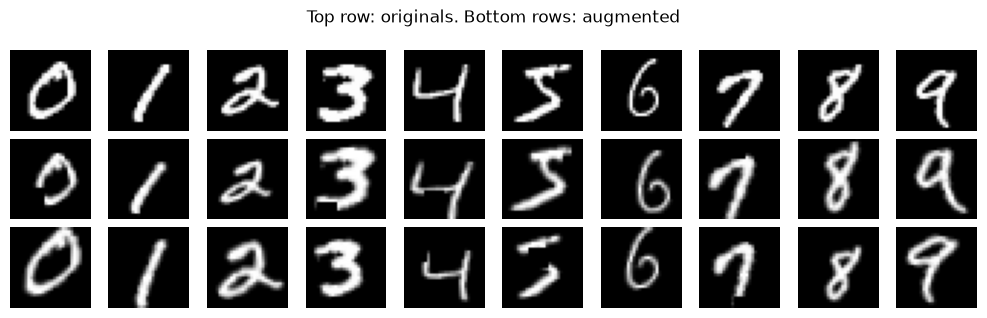

In [4]:
# This block is Generated from Anthropic Claude
# Augmented digits should still be readable
demo_cfg = {**BASELINE, "rotation": 15, "translate": 0.1, "scale_jitter": 0.15, "shear": 10, "cutout": 6}
torch.manual_seed(SEED)
fig, axes = plt.subplots(3, 10, figsize=(10, 3.2))
for col in range(10):
    x = X_train[y_train == col][:1]
    axes[0, col].imshow(x[0, 0].cpu(), cmap="gray")
    for row in (1, 2):
        axes[row, col].imshow(augment(x, demo_cfg)[0, 0].cpu(), cmap="gray")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Top row: originals. Bottom rows: augmented")
plt.tight_layout()
plt.show()

In [5]:
# This block is Generated from Anthropic Claude
# A correct training loop should be able to memorize a small batch
small = CNN(BASELINE).to(DEVICE)
opt = torch.optim.Adam(small.parameters(), lr=1e-3)
xb, yb = X_train[:256], y_train[:256]
for _ in range(100):
    loss = F.cross_entropy(small(xb), yb)
    opt.zero_grad()
    loss.backward()
    opt.step()
small_acc = accuracy(small, xb, yb)
print(f"256-image overfit accuracy: {small_acc:.4f}")
assert small_acc > 0.99

256-image overfit accuracy: 1.0000


In [6]:
# This block is Generated from Anthropic Claude
start = time.time()
_, timing_val = run_training({**BASELINE, "n_blocks": 3, "use_batchnorm": True, "rotation": 10, "translate": 0.1}, SEED, 1)
print(f"one augmented epoch: {time.time() - start:.1f}s, val acc {timing_val[-1]:.4f}")

one augmented epoch: 6.4s, val acc 0.9789


## Part 1: Manual exploration

Starting from a plain baseline (2 blocks, 32 filters, Adam at 1e-3, no regularization), each setting changes one factor and trains for 10 epochs with 2 seeds. Differences on MNIST are near 0.1%, so one seed can't separate signal from noise. The score is the mean validation accuracy over the last 3 epochs, which is less jumpy than the final epoch.

Changing one factor at a time can't show interactions, so the `combined` group tries several helpful settings together.

In [7]:
# This block is Generated from Anthropic Claude
MANUAL_EPOCHS = 10
MANUAL_SEEDS = [SEED, SEED + 1]

AUG_ALL = {"rotation": 10, "translate": 0.1, "scale_jitter": 0.1}
EXPERIMENTS = {
    "baseline": {"baseline": {}},
    "depth": {f"{n} blocks": {"n_blocks": n} for n in (3, 4)},
    "width": {f"{n} filters": {"base_filters": n} for n in (16, 64)},
    "batchnorm": {"on": {"use_batchnorm": True}},
    "head": {"global avg pool": {"head": "gap", "n_blocks": 3}, "flatten (3 blocks)": {"n_blocks": 3}},
    "rotation": {f"±{d}°": {"rotation": d} for d in (5, 10, 20)},
    "translate": {f"{int(t * 100)}%": {"translate": t} for t in (0.05, 0.1, 0.2)},
    "scale_shear": {"mild": {"scale_jitter": 0.1, "shear": 10}},
    "cutout": {"6 px": {"cutout": 6}},
    "dropout": {f"{p}": {"dropout": p} for p in (0.25, 0.5)},
    "weight_decay": {f"{w}": {"weight_decay": w} for w in (1e-4, 1e-3, 1e-2)},
    "label_smoothing": {"0.1": {"label_smoothing": 0.1}},
    "learning_rate": {f"{lr}": {"lr": lr} for lr in (1e-4, 1e-2)},
    "schedule": {"onecycle": {"schedule": "onecycle"}},
    "combined": {
        "bn + onecycle": {"n_blocks": 3, "use_batchnorm": True, "schedule": "onecycle"},
        "bn + onecycle + aug": {"n_blocks": 3, "use_batchnorm": True, "schedule": "onecycle", **AUG_ALL},
        "bn + onecycle + aug + dropout": {"n_blocks": 3, "use_batchnorm": True, "schedule": "onecycle",
                                          "dropout": 0.25, **AUG_ALL},
    },
}

manual_path = RESULTS_DIR / "manual.csv"
columns = ["group", "setting", "seed", "val_acc", "final_val_acc", "seconds"]
manual = pd.read_csv(manual_path) if manual_path.exists() else pd.DataFrame(columns=columns)

for group, settings in EXPERIMENTS.items():
    for setting, change in settings.items():
        for seed in MANUAL_SEEDS:
            done = (manual.group == group) & (manual.setting == setting) & (manual.seed == seed)
            if done.any():
                continue
            start = time.time()
            _, val_acc = run_training({**BASELINE, **change}, seed, MANUAL_EPOCHS)
            row = [group, setting, seed, np.mean(val_acc[-3:]), val_acc[-1], time.time() - start]
            manual.loc[len(manual)] = row
            manual.to_csv(manual_path, index=False)
            print(group, setting, seed, f"{row[3]:.4f}", f"{row[5]:.0f}s", flush=True)

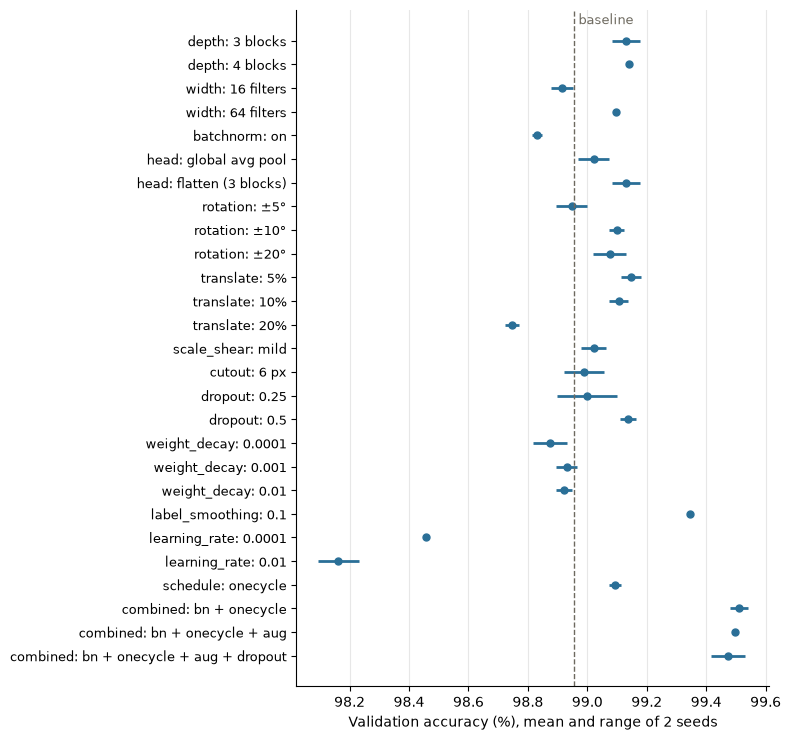

,group,setting,val_acc,low,high,seconds
0,baseline,baseline,0.9896,0.9895,0.9896,17.7588
1,depth,3 blocks,0.9913,0.9908,0.9918,24.3740
2,depth,4 blocks,0.9914,0.9914,0.9914,30.6912
3,width,16 filters,0.9891,0.9888,0.9895,8.6332
4,width,64 filters,0.9910,0.9909,0.9910,47.7049
5,batchnorm,on,0.9883,0.9881,0.9885,19.6458
6,head,global avg pool,0.9902,0.9897,0.9907,24.3531
7,head,flatten (3 blocks),0.9913,0.9908,0.9918,24.3828
8,rotation,±5°,0.9895,0.9889,0.9900,18.2205
9,rotation,±10°,0.9910,0.9907,0.9912,18.1492


In [8]:
# This block is Generated from Anthropic Claude
summary = (manual.groupby(["group", "setting"], sort=False)
           .agg(val_acc=("val_acc", "mean"), low=("val_acc", "min"), high=("val_acc", "max"), seconds=("seconds", "mean"))
           .reset_index())
base = summary.loc[summary.group == "baseline", "val_acc"].item()

plot = summary[summary.group != "baseline"].iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.hlines(plot.index, plot.low * 100, plot.high * 100, color="#2a6f97", lw=2)
ax.plot(plot.val_acc * 100, plot.index, "o", color="#2a6f97", ms=5)
ax.axvline(base * 100, color="#6d695f", lw=1, ls="--")
ax.text(base * 100, len(plot) - 0.3, " baseline", color="#6d695f", fontsize=9)
ax.set_yticks(plot.index, plot.group + ": " + plot.setting, fontsize=9)
ax.set_xlabel("Validation accuracy (%), mean and range of 2 seeds")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
summary.round(4)

### Observations from manual exploration

The baseline reached 98.96% validation accuracy. The values below are the means of 2 seeds after 10 epochs.

**What helped**
- **Depth:** 3 blocks reached 99.13%, and a 4th added nothing (99.14%) while costing more time.
- **Label smoothing:** 0.1 gave the largest single-change gain, at 99.35%.
- **Mild augmentation:** ±10° rotation reached 99.10% and 5% translation reached 99.15%.
- **Width:** 64 filters reached 99.10%, but each run took about 2.7× as long.
- **Combining:** 3 blocks, BatchNorm and OneCycle together reached 99.51%, which beats any single change by a wide margin.

**What didn't help, or hurt**
- **BatchNorm alone** dropped to 98.83% with a constant learning rate. It only paid off alongside a schedule, which is exactly what one-factor-at-a-time testing would miss.
- **Heavy translation:** 20% hurt (98.75%), since it pushes digits partly out of frame.
- **Weight decay** showed no clear effect from 1e-4 to 1e-2 (98.87% to 98.93%).
- **Learning rate:** both 1e-4 (98.46%) and 1e-2 (98.16%) were clearly worse than 1e-3.
- **Global average pooling** was slightly below flatten at 3 blocks (99.02% against 99.13%).

Adding augmentation to the combined model didn't help within 10 epochs (99.50% against 99.51%). Augmented models usually need longer to benefit, so the search uses 15 epochs. Differences under about 0.1% are at the level of seed noise: dropout 0.25 scored below 0.5, for example, which is unlikely to be a real trend.

### Hyperparameter space and why

The manual results set these ranges. OneCycle was fixed on because it clearly helped, and shear and cutout were left out because neither stood out, which keeps the space smaller for a 50-trial budget.

| Parameter | Range | Why |
|---|---|---|
| `lr` | 3e-4 to 5e-3, log | 1e-4 and 1e-2 were both clearly worse. OneCycle peaks can go higher than a constant rate |
| `weight_decay` | 1e-6 to 1e-2, log | No manual effect, so left wide for the search to test with other settings |
| `batch_size` | 64, 128, 256 | Interacts with learning rate |
| `n_blocks` | 2 to 4 | Depth helped up to 3, and the 28×28 input limits it to 4 |
| `base_filters` | 16 to 64, step 16 | Capacity against training time |
| `use_batchnorm` | on, off | Helped only in combination, so it's worth testing with other settings |
| `head` | flatten, global average pooling | Close in manual runs |
| `dropout` | 0 to 0.5 | Manual results were noisy, so a range is better than a fixed value |
| `label_smoothing` | 0 to 0.15 | Strongest single change |
| `rotation` | 0 to 20° | ±10° and ±20° both helped. Beyond that, digits start to lose their meaning |
| `translate` | 0 to 0.15 | 20% hurt, so the upper limit sits below it |
| `scale_jitter` | 0 to 0.2 | Handwriting size varies |

## Part 2: Optuna search

The search maximizes validation accuracy after 15 epochs. It uses a seeded TPE sampler, which models which regions scored well, and a median pruner, which stops trials that are behind other trials at the same epoch. The pruner waits 8 trials and 6 epochs, because OneCycle runs look bad early while the learning rate is high. The study is stored in SQLite, so an interrupted search resumes where it stopped.

In [9]:
# This block is Generated from Anthropic Claude
N_TRIALS = 50
SEARCH_EPOCHS = 15


def suggest_config(trial):
    return {
        "lr": trial.suggest_float("lr", 3e-4, 5e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [64, 128, 256]),
        "n_blocks": trial.suggest_int("n_blocks", 2, 4),
        "base_filters": trial.suggest_int("base_filters", 16, 64, step=16),
        "use_batchnorm": trial.suggest_categorical("use_batchnorm", [True, False]),
        "head": trial.suggest_categorical("head", ["flatten", "gap"]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "label_smoothing": trial.suggest_float("label_smoothing", 0.0, 0.15),
        "rotation": trial.suggest_float("rotation", 0.0, 20.0),
        "translate": trial.suggest_float("translate", 0.0, 0.15),
        "scale_jitter": trial.suggest_float("scale_jitter", 0.0, 0.2),
        "shear": 0.0, "cutout": 0, "schedule": "onecycle",
    }


def objective(trial):
    _, val_acc = run_training(suggest_config(trial), SEED, SEARCH_EPOCHS, trial=trial)
    return val_acc[-1]


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    study_name="mnist_cnn",
    storage=f"sqlite:///{RESULTS_DIR / 'optuna.db'}",
    load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=6),
)
finished = [t for t in study.trials if t.state.is_finished()]
study.optimize(objective, n_trials=max(0, N_TRIALS - len(finished)))

states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(states.to_string())
print("best validation accuracy:", study.best_value)
print(json.dumps(study.best_params, indent=2))

COMPLETE    28
PRUNED      22
best validation accuracy: 0.9967003299670033
{
  "lr": 0.004260582349856903,
  "weight_decay": 0.0004098116072766115,
  "batch_size": 128,
  "n_blocks": 3,
  "base_filters": 64,
  "use_batchnorm": true,
  "head": "gap",
  "dropout": 0.47487700280720063,
  "label_smoothing": 0.11056449473408665,
  "rotation": 8.133893311546661,
  "translate": 0.10215602097379867,
  "scale_jitter": 0.015632402576443168
}


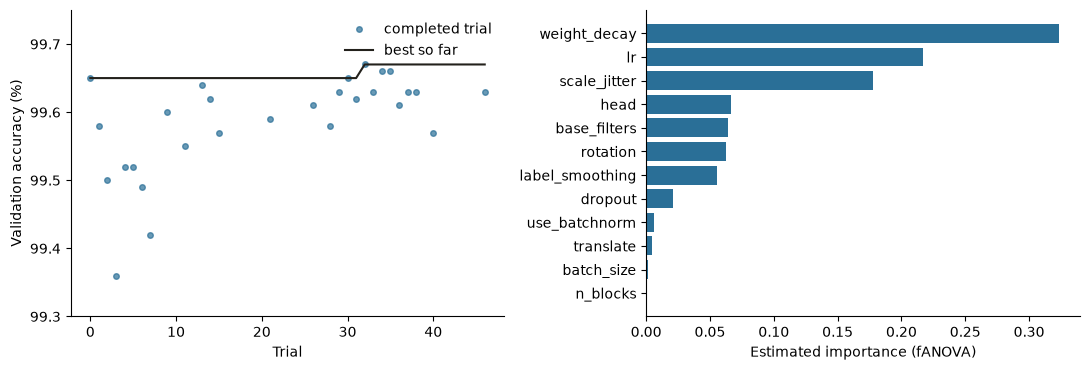

,lr,weight_decay,batch_size,n_blocks,base_filters,use_batchnorm,head,dropout,label_smoothing,rotation,translate,scale_jitter,val_acc
19,0.0043,0.0004,128,3,64,True,gap,0.4749,0.1106,8.1339,0.1022,0.0156,0.9967
22,0.0037,0.0008,128,3,64,True,gap,0.3628,0.1172,8.8720,0.0805,0.0206,0.9966
21,0.0031,0.0003,128,3,64,True,gap,0.3804,0.0879,5.9827,0.1483,0.0354,0.9966
0,0.0022,0.0050,128,3,64,True,flatten,0.3994,0.0348,6.2490,0.1346,0.1069,0.9965
17,0.0033,0.0003,128,3,64,True,gap,0.4905,0.1002,8.1523,0.1189,0.0221,0.9965
10,0.0028,0.0003,128,3,64,True,flatten,0.3900,0.1198,7.2198,0.1299,0.0592,0.9964
25,0.0042,0.0005,128,3,64,True,gap,0.4149,0.0965,7.7472,0.0512,0.0635,0.9963
24,0.0044,0.0001,256,3,64,True,gap,0.4066,0.1145,9.7653,0.1048,0.0267,0.9963


In [10]:
# This block is Generated from Anthropic Claude
trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
numbers = [t.number for t in trials]
values = [t.value * 100 for t in trials]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(numbers, values, "o", color="#2a6f97", ms=4, alpha=0.7, label="completed trial")
axes[0].plot(numbers, np.maximum.accumulate(values), color="#23211c", lw=1.5, label="best so far")
axes[0].set_ylim(99.3, 99.75)
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].legend(frameon=False)
importance = optuna.importance.get_param_importances(study, target=None)
names = list(importance)[::-1]
axes[1].barh(names, [importance[n] for n in names], color="#2a6f97")
axes[1].set_xlabel("Estimated importance (fANOVA)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

top = (pd.DataFrame([{**t.params, "val_acc": t.value} for t in trials])
       .sort_values("val_acc", ascending=False).head(8))
display(top.round(4))

## Part 3: Final model

The best trial's configuration is frozen here, before the test set is loaded. It trains for 30 epochs on the training split with 5 seeds. All 5 test results are reported, because picking the best seed by test accuracy would turn the test set into another selection step.

In [11]:
# This block is Generated from Anthropic Claude
FINAL_EPOCHS = 30
FINAL_SEEDS = [SEED + i for i in range(5)]

best = study.best_params
FINAL_CFG = {**best, "shear": 0.0, "cutout": 0, "schedule": "onecycle"}
print(json.dumps(FINAL_CFG, indent=2))

# The test set is loaded here and nowhere earlier
mnist_test = MNIST(DATA_DIR, train=False, download=True)
X_test = ((mnist_test.data.float().unsqueeze(1) / 255.0 - MEAN) / STD).to(DEVICE)
y_test = mnist_test.targets.to(DEVICE)

final_path = RESULTS_DIR / "final.csv"
final = pd.read_csv(final_path) if final_path.exists() else pd.DataFrame(columns=["seed", "val_acc", "test_acc"])
for seed in FINAL_SEEDS:
    ckpt = RESULTS_DIR / f"final_seed{seed}.pt"
    if (final.seed == seed).any():
        continue
    model, val_curve = run_training(FINAL_CFG, seed, FINAL_EPOCHS)
    torch.save(model.state_dict(), ckpt)
    final.loc[len(final)] = [seed, val_curve[-1], accuracy(model, X_test, y_test)]
    final.to_csv(final_path, index=False)
    print(int(seed), f"val {val_curve[-1]:.4f}", flush=True)

print(final.round(4).to_string(index=False))
print(f"test accuracy: {final.test_acc.mean() * 100:.2f}% ± {final.test_acc.std() * 100:.2f}% over {len(final)} seeds")
print(f"validation accuracy: {final.val_acc.mean() * 100:.2f}% ± {final.val_acc.std() * 100:.2f}%")

{
  "lr": 0.004260582349856903,
  "weight_decay": 0.0004098116072766115,
  "batch_size": 128,
  "n_blocks": 3,
  "base_filters": 64,
  "use_batchnorm": true,
  "head": "gap",
  "dropout": 0.47487700280720063,
  "label_smoothing": 0.11056449473408665,
  "rotation": 8.133893311546661,
  "translate": 0.10215602097379867,
  "scale_jitter": 0.015632402576443168,
  "shear": 0.0,
  "cutout": 0,
  "schedule": "onecycle"
}
 seed  val_acc  test_acc
577.0   0.9964    0.9971
578.0   0.9961    0.9972
579.0   0.9967    0.9973
580.0   0.9964    0.9974
581.0   0.9963    0.9976
test accuracy: 99.73% ± 0.02% over 5 seeds
validation accuracy: 99.64% ± 0.02%


29 test errors for the first seed


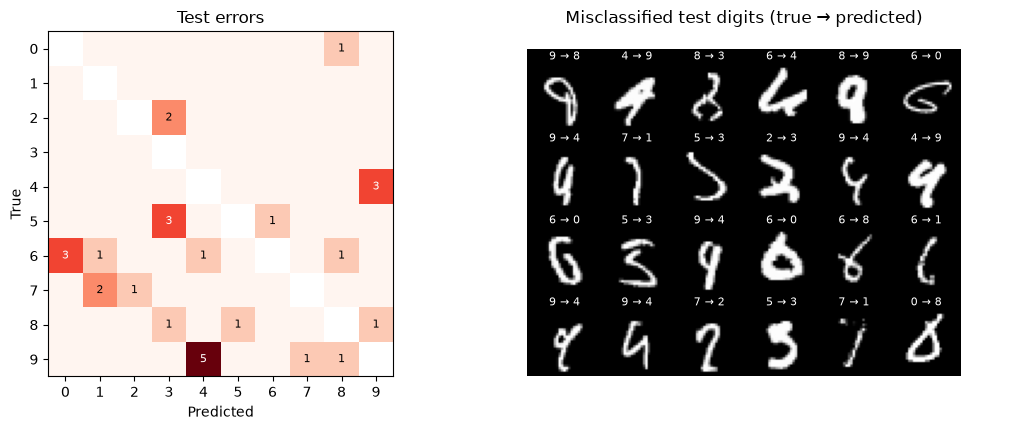

In [12]:
# This block is Generated from Anthropic Claude
model = CNN(FINAL_CFG).to(DEVICE)
model.load_state_dict(torch.load(RESULTS_DIR / f"final_seed{FINAL_SEEDS[0]}.pt", map_location=DEVICE))
model.eval()
with torch.no_grad():
    pred = torch.cat([model(X_test[i : i + 2048]).argmax(1) for i in range(0, len(X_test), 2048)])
wrong = (pred != y_test).nonzero().flatten().cpu()
print(len(wrong), "test errors for the first seed")

matrix = torch.zeros(10, 10, dtype=int)
for t, p in zip(y_test.cpu(), pred.cpu()):
    matrix[t, p] += 1
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
errors_only = matrix.clone().float()
errors_only.fill_diagonal_(float("nan"))
axes[0].imshow(errors_only, cmap="Reds")
for r in range(10):
    for c in range(10):
        if r != c and matrix[r, c]:
            axes[0].text(c, r, int(matrix[r, c]), ha="center", va="center", fontsize=8,
                         color="white" if matrix[r, c] >= 3 else "black")
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(10))
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Test errors")
axes[1].axis("off")
axes[1].set_title("Misclassified test digits (true → predicted)")
inner = axes[1].inset_axes([0, 0, 1, 0.95])
inner.axis("off")
show = wrong[:24]
canvas = torch.zeros(4 * 34, 6 * 30)
for i, idx in enumerate(show):
    r, c = i // 6, i % 6
    canvas[r * 34 + 6 : r * 34 + 34, c * 30 + 1 : c * 30 + 29] = X_test[idx, 0].cpu() * STD + MEAN
    inner.text(c * 30 + 15, r * 34 + 4, f"{y_test[idx].item()} → {pred[idx].item()}", ha="center", fontsize=8, color="white")
inner.imshow(canvas, cmap="gray")
plt.tight_layout()
plt.show()

## Report

### Network

The final network has 3 convolutional blocks with 64, 128 and 256 filters. Each block is two 3×3 convolutions, each followed by BatchNorm and ReLU, then a 2×2 max pool. Global average pooling feeds dropout and a linear 10-class output. It has about 1.15 million parameters. Training uses AdamW with a OneCycle schedule, label-smoothed cross-entropy, and random rotation, translation and scaling on training batches only.

### Search observations

Of the 50 trials, 28 finished and 22 were pruned. Finished trials had a median of 99.61% and a best of 99.67%, so most of the space was already good.

- **Architecture:** the search settled quickly on 3 blocks (24 of 28 finished trials) and 64 filters (18 of 28). Mean accuracy rose with width, from 99.43% at 16 filters to 99.63% at 64.
- **BatchNorm** averaged 99.61% against 99.52% without it, which agrees with the manual finding once a schedule is in place.
- **Regularization:** the best trials used high dropout (0.36 to 0.49) and label smoothing near 0.1.
- **Augmentation:** the best trials stayed mild, with rotation around 6° to 10° and little scale jitter. This matches the manual result that strong augmentation costs accuracy.
- **Global average pooling** did better here than in manual runs, averaging 99.61% against 99.57% for flatten. The difference is small, and with 64 filters and heavy dropout it may depend on those settings.

The importance plot needs care. It puts weight decay and learning rate first, yet it only sees finished trials, and the sampler concentrated on a narrow region. The very low importance of `n_blocks` mainly reflects that nearly every finished trial used 3 blocks, not that depth doesn't matter. The manual results show it does.

### Final hyperparameters and test accuracy

| Parameter | Value |
|---|---|
| `lr` | 0.00426 |
| `weight_decay` | 0.00041 |
| `batch_size` | 128 |
| `n_blocks` | 3 |
| `base_filters` | 64 |
| `use_batchnorm` | True |
| `head` | global average pooling |
| `dropout` | 0.475 |
| `label_smoothing` | 0.111 |
| `rotation` | 8.13° |
| `translate` | 0.102 |
| `scale_jitter` | 0.016 |
| Schedule | OneCycle, 30 epochs |

**Test accuracy: 99.73% ± 0.02% over 5 seeds** (individual seeds 99.71% to 99.76%). Validation accuracy was 99.64% ± 0.02%. This clears the 99% target.

### Why separate validation and test sets matter

Every choice here was made by looking at validation accuracy: the manual comparisons and all 50 Optuna trials. That makes validation part of the fitting process, because choosing the best of many trials favours whichever one happened to suit those particular 10,001 images. The best trial scored 99.67%, and retraining that configuration gave 99.64%, a small but visible sign of that optimism.

A test set that played no part in those decisions gives an estimate that isn't biased by the selection. Here it was only loaded after the configuration was frozen, and all 5 seeds are reported so that it wasn't used to pick one either.

Test accuracy came out above validation (99.73% against 99.64%). That doesn't mean the model generalizes better than it fits: the two sets just differ in difficulty, and with about 10k images and accuracy near 99.7%, the standard error of each estimate is about 0.05%. The comparison also shows why tiny differences between top trials shouldn't be overinterpreted, since they're around the size of that noise.